# Detector de dents impactades amb Faster R-CNN amb augmentation i fine-tuning


Objectiu: passar de classificar tota l'ortopantomografia a predir directament les posicions de les dents impactades.

El model aprendrà una única classe clínica:

- `0`: background, reservat internament pel detector.
- `1`: dent impactada.

Les anotacions DENTEX tenen les boxes en format `[x, y, amplada, altura]`. Faster R-CNN necessita `[x_min, y_min, x_max, y_max]`, així que el dataset farà la conversió.

Aquest és un primer baseline: sense augmentacions, una sola classe i mètriques senzilles a IoU 0.5.

In [1]:
from pathlib import Path
from collections import defaultdict
import json
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

import torch
import torchvision
from torch.utils.data import (
    Dataset,
    DataLoader,
    Subset,
    ConcatDataset
)
from torchvision.transforms import functional as TF


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti


In [2]:
from pathlib import Path

project_paths = {
    "Training JSON": Path(
        "data/raw/dentex/training_data/"
        "quadrant-enumeration-disease/"
        "train_quadrant_enumeration_disease.json"
    ),

    "Training images": Path(
        "data/raw/dentex/training_data/"
        "quadrant-enumeration-disease/xrays"
    ),

    "Validation JSON": Path(
        "data/raw/dentex/validation_triple.json"
    ),

    "Validation images": Path(
        "data/raw/dentex/validation_data/"
        "quadrant_enumeration_disease/xrays"
    ),

    "Detector checkpoint": Path(
        "models/fasterrcnn_impacted_best.pt"
    ),

    "Results directory": Path(
        "results"
    )
}

for name, path in project_paths.items():
    print(
        f"{name:22} | "
        f"{'EXISTEIX' if path.exists() else 'NO EXISTEIX'} | "
        f"{path.resolve()}"
    )

Training JSON          | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\data\raw\dentex\training_data\quadrant-enumeration-disease\train_quadrant_enumeration_disease.json
Training images        | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\data\raw\dentex\training_data\quadrant-enumeration-disease\xrays
Validation JSON        | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\data\raw\dentex\validation_triple.json
Validation images      | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\data\raw\dentex\validation_data\quadrant_enumeration_disease\xrays
Detector checkpoint    | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\models\fasterrcnn_impacted_best.pt
Results directory      | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\results


In [3]:
data_dir = Path("data/raw/dentex")

train_images_dir = (
    data_dir
    / "training_data"
    / "quadrant-enumeration-disease"
    / "xrays"
)

val_images_dir = (
    data_dir
    / "validation_data"
    / "quadrant_enumeration_disease"
    / "xrays"
)

train_json_path = (
    data_dir
    / "training_data"
    / "quadrant-enumeration-disease"
    / "train_quadrant_enumeration_disease.json"
)

val_json_path = data_dir / "validation_triple.json"

with open(train_json_path, "r") as file:
    train_data = json.load(file)

with open(val_json_path, "r") as file:
    val_data = json.load(file)


def find_diagnosis_id(data, diagnosis_name):
    """
    Busca l'id real al JSON en lloc de suposar que impacted sempre és 0.
    """
    diagnosis_name = diagnosis_name.lower()

    for category in data["categories_3"]:
        if diagnosis_name in category["name"].lower():
            return category["id"]

    raise ValueError(
        f"No s'ha trobat el diagnòstic: {diagnosis_name}"
    )


train_impacted_id = find_diagnosis_id(train_data, "impacted")
val_impacted_id = find_diagnosis_id(val_data, "impacted")

assert train_impacted_id == val_impacted_id
impacted_category_id = train_impacted_id

print("Train images:", len(train_data["images"]))
print("Validation images:", len(val_data["images"]))
print("ID de la categoria impacted:", impacted_category_id)
print("Categories de diagnòstic:", train_data["categories_3"])



Train images: 705
Validation images: 50
ID de la categoria impacted: 0
Categories de diagnòstic: [{'id': 0, 'name': 'Impacted', 'supercategory': 'Impacted'}, {'id': 1, 'name': 'Caries', 'supercategory': 'Caries'}, {'id': 2, 'name': 'Periapical Lesion', 'supercategory': 'Periapical Lesion'}, {'id': 3, 'name': 'Deep Caries', 'supercategory': 'Deep Caries'}]


In [4]:
class DentexImpactedDetectionDataset(Dataset):
    def __init__(
        self,
        data,
        images_dir,
        impacted_category_id,
        augment=False
    ):
        self.images = data["images"]
        self.images_dir = Path(images_dir)
        self.impacted_category_id = impacted_category_id
        self.augment = augment

        self.impacted_annotations = defaultdict(list)

        for annotation in data["annotations"]:
            if (
                annotation["category_id_3"]
                == self.impacted_category_id
            ):
                self.impacted_annotations[
                    annotation["image_id"]
                ].append(annotation)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]
        image_id = image_info["id"]

        image_path = (
            self.images_dir
            / image_info["file_name"]
        )

        pil_image = Image.open(
            image_path
        ).convert("RGB")

        image_width, image_height = pil_image.size

        # Tensor float entre 0 i 1.
        image = (
            TF.pil_to_tensor(pil_image).float()
            / 255.0
        )

        boxes = []

        for annotation in self.impacted_annotations.get(
            image_id,
            []
        ):
            x, y, width, height = map(
                float,
                annotation["bbox"]
            )

            x_min = max(0.0, x)
            y_min = max(0.0, y)
            x_max = min(
                float(image_width),
                x + width
            )
            y_max = min(
                float(image_height),
                y + height
            )

            if x_max > x_min and y_max > y_min:
                boxes.append([
                    x_min,
                    y_min,
                    x_max,
                    y_max
                ])

        if boxes:
            boxes = torch.tensor(
                boxes,
                dtype=torch.float32
            )
        else:
            boxes = torch.zeros(
                (0, 4),
                dtype=torch.float32
            )

        # AUGMENTACIONS: només s'executen a training.
        if self.augment:

            # Flip horitzontal.
            if random.random() < 0.5:
                image = TF.hflip(image)

                if len(boxes) > 0:
                    old_x_min = boxes[:, 0].clone()
                    old_x_max = boxes[:, 2].clone()

                    boxes[:, 0] = (
                        image_width - old_x_max
                    )
                    boxes[:, 2] = (
                        image_width - old_x_min
                    )

            # Variació moderada de llum.
            if random.random() < 0.5:
                brightness_factor = random.uniform(
                    0.85,
                    1.15
                )

                image = TF.adjust_brightness(
                    image,
                    brightness_factor
                )

            # Variació moderada de contrast.
            if random.random() < 0.5:
                contrast_factor = random.uniform(
                    0.85,
                    1.15
                )

                image = TF.adjust_contrast(
                    image,
                    contrast_factor
                )

            image = image.clamp(0.0, 1.0)

        labels = torch.ones(
            (boxes.shape[0],),
            dtype=torch.int64
        )

        area = (
            (boxes[:, 2] - boxes[:, 0])
            * (boxes[:, 3] - boxes[:, 1])
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([image_id]),
            "area": area,
            "iscrowd": torch.zeros(
                (boxes.shape[0],),
                dtype=torch.int64
            )
        }

        return image, target

    def file_name(self, index):
        return self.images[index]["file_name"]

In [5]:
train_dataset = DentexImpactedDetectionDataset(
    train_data,
    train_images_dir,
    impacted_category_id,
    augment=True
)

# Training original, sense augmentacions
# Només per comparar i buscar hard negatives
train_mining_dataset = DentexImpactedDetectionDataset(
    train_data,
    train_images_dir,
    impacted_category_id,
    augment=False
)

val_dataset = DentexImpactedDetectionDataset(
    val_data,
    val_images_dir,
    impacted_category_id
)


def dataset_summary(dataset):
    boxes_per_image = [
        len(dataset.impacted_annotations.get(info["id"], []))
        for info in dataset.images
    ]

    return {
        "images": len(dataset),
        "positive_images": sum(n > 0 for n in boxes_per_image),
        "negative_images": sum(n == 0 for n in boxes_per_image),
        "impacted_boxes": sum(boxes_per_image)
    }


display(pd.DataFrame([
    {"split": "train", **dataset_summary(train_dataset)},
    {"split": "validation", **dataset_summary(val_dataset)}
]))

# Comprovacions bàsiques.
image, target = train_dataset[0]
print("Forma de la imatge:", image.shape)
print("Forma de boxes:", target["boxes"].shape)
print("Labels:", target["labels"])



,split,images,positive_images,negative_images,impacted_boxes
0,train,705,254,451,604
1,validation,50,16,34,40


Forma de la imatge: torch.Size([3, 1316, 2744])
Forma de boxes: torch.Size([2, 4])
Labels: tensor([1, 1])


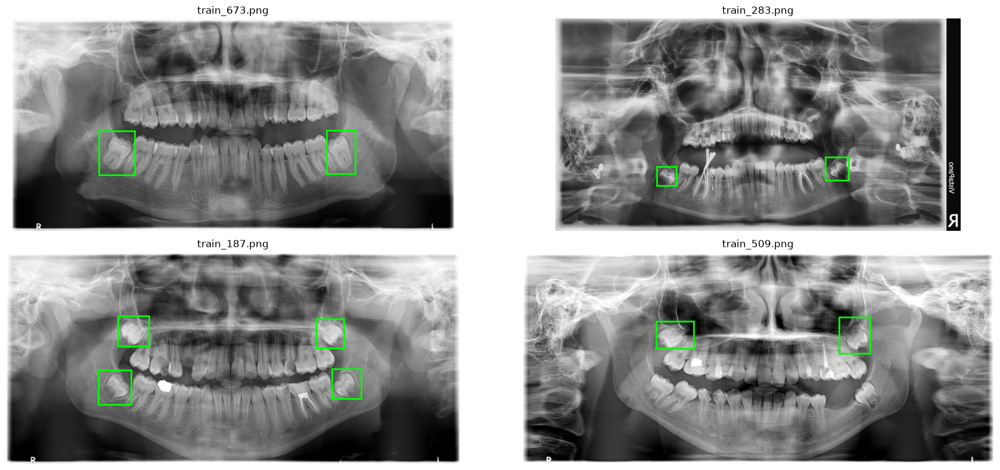

In [6]:
positive_train_indices = [
    index
    for index, image_info in enumerate(
        train_dataset.images
    )
    if len(
        train_dataset.impacted_annotations.get(
            image_info["id"],
            []
        )
    ) > 0
]

figure, axes = plt.subplots(
    2,
    2,
    figsize=(18, 8)
)

for axis, index in zip(
    axes.flatten(),
    positive_train_indices[:4]
):
    image, target = train_dataset[index]

    axis.imshow(
        image.permute(1, 2, 0).numpy()
    )

    for box in target["boxes"]:
        x_min, y_min, x_max, y_max = box

        axis.add_patch(
            Rectangle(
                (
                    x_min.item(),
                    y_min.item()
                ),
                (x_max - x_min).item(),
                (y_max - y_min).item(),
                edgecolor="lime",
                facecolor="none",
                linewidth=2
            )
        )

    axis.set_title(
        train_dataset.file_name(index)
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

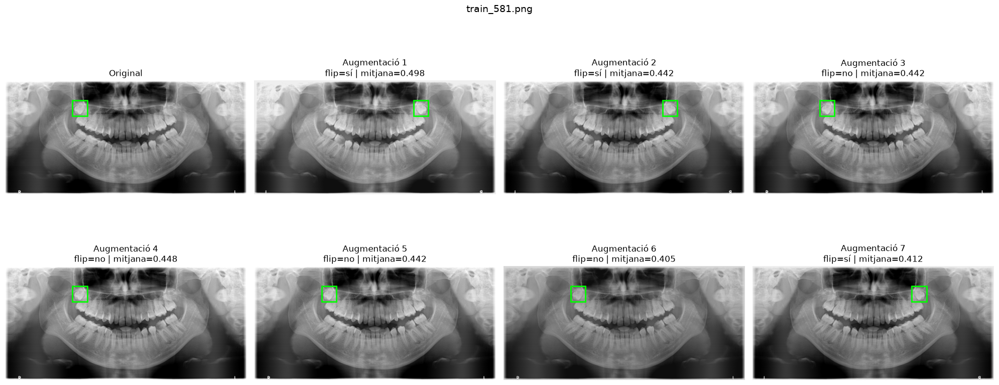

In [7]:
# Busquem una imatge amb exactament una impactació,
# perquè sigui fàcil veure si la box es gira.
demo_index = next(
    index
    for index, image_info in enumerate(
        train_dataset.images
    )
    if len(
        train_dataset.impacted_annotations.get(
            image_info["id"],
            []
        )
    ) == 1
)

original_image, original_target = (
    train_mining_dataset[demo_index]
)

image_width = original_image.shape[2]

# Calculem on hauria d'estar la box si fem flip.
expected_flipped_boxes = (
    original_target["boxes"].clone()
)

old_x_min = expected_flipped_boxes[:, 0].clone()
old_x_max = expected_flipped_boxes[:, 2].clone()

expected_flipped_boxes[:, 0] = (
    image_width - old_x_max
)

expected_flipped_boxes[:, 2] = (
    image_width - old_x_min
)

samples = [
    (
        "Original",
        original_image,
        original_target
    )
]

# Cada crida a train_dataset pot generar
# una augmentació diferent.
for sample_number in range(7):
    augmented_image, augmented_target = (
        train_dataset[demo_index]
    )

    was_flipped = torch.allclose(
        augmented_target["boxes"],
        expected_flipped_boxes,
        atol=1e-4
    )

    title = (
        f"Augmentació {sample_number + 1}\n"
        f"flip={'sí' if was_flipped else 'no'} | "
        f"mitjana={augmented_image.mean():.3f}"
    )

    samples.append(
        (
            title,
            augmented_image,
            augmented_target
        )
    )

figure, axes = plt.subplots(
    2,
    4,
    figsize=(20, 9)
)

for axis, (title, image, target) in zip(
    axes.flatten(),
    samples
):
    axis.imshow(
        image.permute(1, 2, 0).numpy()
    )

    for box in target["boxes"]:
        x_min, y_min, x_max, y_max = box

        axis.add_patch(
            Rectangle(
                (
                    x_min.item(),
                    y_min.item()
                ),
                (x_max - x_min).item(),
                (y_max - y_min).item(),
                edgecolor="lime",
                facecolor="none",
                linewidth=2
            )
        )

    axis.set_title(title)
    axis.axis("off")

figure.suptitle(
    train_dataset.file_name(demo_index),
    fontsize=14
)

plt.tight_layout()
plt.show()

In [8]:
print(
    "train_dataset.augment:",
    getattr(train_dataset, "augment", "NO EXISTEIX")
)

print(
    "train_mining_dataset.augment:",
    getattr(
        train_mining_dataset,
        "augment",
        "NO EXISTEIX"
    )
)

print(
    "train_dataset utilitza la classe actual:",
    train_dataset.__class__
    is DentexImpactedDetectionDataset
)


train_dataset.augment: True
train_mining_dataset.augment: False
train_dataset utilitza la classe actual: True


In [9]:
def collate_fn(batch):
    # Les imatges poden tenir mides diferents i cada imatge
    # pot tenir un nombre diferent de boxes.
    return tuple(zip(*batch))


batch_size = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)


# Comprovacions importants
assert train_loader.dataset is train_dataset
assert train_loader.dataset.augment is True
assert val_loader.dataset.augment is False

print(
    "Training utilitza augmentacions:",
    train_loader.dataset.augment
)

print(
    "Validation utilitza augmentacions:",
    val_loader.dataset.augment
)

images, targets = next(iter(train_loader))

print("Imatges al batch:", len(images))
print(
    "Boxes per imatge:",
    [len(target["boxes"]) for target in targets]
)

Training utilitza augmentacions: True
Validation utilitza augmentacions: False
Imatges al batch: 2
Boxes per imatge: [0, 0]


In [10]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


def build_detector(pretrained=True):
    if pretrained:
        model = fasterrcnn_resnet50_fpn(
            weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
            trainable_backbone_layers=3,
            min_size=512,
            max_size=1600
        )
    else:
        # Per reconstruir l'arquitectura abans de carregar el checkpoint.
        model = fasterrcnn_resnet50_fpn(
            weights=None,
            weights_backbone=None,
            min_size=512,
            max_size=1600
        )

    input_features = (
        model.roi_heads.box_predictor.cls_score.in_features
    )

    # Dues classes totals: background + impacted.
    model.roi_heads.box_predictor = FastRCNNPredictor(
        input_features,
        num_classes=2
    )

    return model


# Reiniciem les seeds abans de crear el model.
# Així la comparació amb el baseline és més reproduïble.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# Model nou carregat amb pesos COCO.
detector = build_detector(
    pretrained=True
).to(device)

print("Detector nou creat.")
print("Device:", device)

Detector nou creat.
Device: cuda


In [11]:
# Smoke test: comprovem que una passada d'entrenament produeix losses.
images, targets = next(iter(train_loader))

images = [image.to(device) for image in images]
targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in targets
]

detector.train()

with torch.no_grad():
    loss_dict = detector(images, targets)

print({
    name: round(value.item(), 4)
    for name, value in loss_dict.items()
})

detector.eval()

{'loss_classifier': 0.6054, 'loss_box_reg': 0.0546, 'loss_objectness': 0.2354, 'loss_rpn_box_reg': 0.0119}


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(512,), max_size=1600, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [12]:
def train_one_epoch(model, data_loader, optimizer, device):
    model.train()
    running_loss = 0.0
    n_images = 0

    for images, targets in data_loader:
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        loss_dict = model(images, targets)
        total_loss = sum(loss_dict.values())

        if not torch.isfinite(total_loss):
            raise RuntimeError(
                f"Loss no finita: {total_loss.item()}"
            )

        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )
        optimizer.step()

        batch_images = len(images)
        running_loss += total_loss.item() * batch_images
        n_images += batch_images

    return running_loss / n_images

In [13]:
from torchvision.ops import box_iou


def match_image_detections(
    predicted_boxes,
    predicted_scores,
    true_boxes,
    score_threshold=0.30,
    iou_threshold=0.50
):
    keep = predicted_scores >= score_threshold
    predicted_boxes = predicted_boxes[keep]
    predicted_scores = predicted_scores[keep]

    # Ordenem de més a menys confiança.
    order = predicted_scores.argsort(descending=True)
    predicted_boxes = predicted_boxes[order]

    if len(predicted_boxes) == 0:
        return 0, 0, len(true_boxes)

    if len(true_boxes) == 0:
        return 0, len(predicted_boxes), 0

    ious = box_iou(predicted_boxes, true_boxes)
    matched_true_boxes = set()
    true_positives = 0
    false_positives = 0

    for prediction_index in range(len(predicted_boxes)):
        best_iou, true_index = ious[prediction_index].max(dim=0)
        true_index = true_index.item()

        if (
            best_iou.item() >= iou_threshold
            and true_index not in matched_true_boxes
        ):
            true_positives += 1
            matched_true_boxes.add(true_index)
        else:
            false_positives += 1

    false_negatives = len(true_boxes) - len(matched_true_boxes)

    return true_positives, false_positives, false_negatives


@torch.no_grad()
def evaluate_detector(
    model,
    data_loader,
    device,
    score_threshold=0.30,
    iou_threshold=0.50
):
    model.eval()

    total_tp = 0
    total_fp = 0
    total_fn = 0

    for images, targets in data_loader:
        images_device = [image.to(device) for image in images]
        outputs = model(images_device)

        for output, target in zip(outputs, targets):
            tp, fp, fn = match_image_detections(
                output["boxes"].cpu(),
                output["scores"].cpu(),
                target["boxes"],
                score_threshold=score_threshold,
                iou_threshold=iou_threshold
            )

            total_tp += tp
            total_fp += fp
            total_fn += fn

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0
        else 0.0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    return {
        "tp": total_tp,
        "fp": total_fp,
        "fn": total_fn,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [14]:
trainable_parameters = [
    parameter
    for parameter in detector.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.SGD(
    trainable_parameters,
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

num_epochs = 8
best_f1 = -1.0

# IMPORTANT: checkpoint diferent del baseline
checkpoint_path = Path(
    "models/fasterrcnn_impacted_aug_best.pt"
)

checkpoint_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

history = []

for epoch in range(num_epochs):

    train_loss = train_one_epoch(
        detector,
        train_loader,
        optimizer,
        device
    )

    validation_metrics = evaluate_detector(
        detector,
        val_loader,
        device,
        score_threshold=0.30,
        iou_threshold=0.50
    )

    scheduler.step()

    epoch_results = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **validation_metrics
    }

    history.append(epoch_results)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"precision: "
        f"{validation_metrics['precision']:.3f} | "
        f"recall: "
        f"{validation_metrics['recall']:.3f} | "
        f"F1: "
        f"{validation_metrics['f1']:.3f} | "
        f"TP/FP/FN: "
        f"{validation_metrics['tp']}/"
        f"{validation_metrics['fp']}/"
        f"{validation_metrics['fn']}"
    )

    if validation_metrics["f1"] > best_f1:
        best_f1 = validation_metrics["f1"]

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": (
                    detector.state_dict()
                ),
                "metrics": validation_metrics
            },
            checkpoint_path
        )

        print(
            "  Checkpoint desat:",
            f"F1={best_f1:.3f}"
        )

history_df = pd.DataFrame(history)

display(history_df)

Epoch 1/8 | train loss: 0.1281 | precision: 0.544 | recall: 0.925 | F1: 0.685 | TP/FP/FN: 37/31/3
  Checkpoint desat: F1=0.685
Epoch 2/8 | train loss: 0.0886 | precision: 0.458 | recall: 0.950 | F1: 0.618 | TP/FP/FN: 38/45/2
Epoch 3/8 | train loss: 0.0814 | precision: 0.607 | recall: 0.925 | F1: 0.733 | TP/FP/FN: 37/24/3
  Checkpoint desat: F1=0.733
Epoch 4/8 | train loss: 0.0627 | precision: 0.587 | recall: 0.925 | F1: 0.718 | TP/FP/FN: 37/26/3
Epoch 5/8 | train loss: 0.0569 | precision: 0.655 | recall: 0.900 | F1: 0.758 | TP/FP/FN: 36/19/4
  Checkpoint desat: F1=0.758
Epoch 6/8 | train loss: 0.0562 | precision: 0.655 | recall: 0.900 | F1: 0.758 | TP/FP/FN: 36/19/4
Epoch 7/8 | train loss: 0.0542 | precision: 0.655 | recall: 0.900 | F1: 0.758 | TP/FP/FN: 36/19/4
Epoch 8/8 | train loss: 0.0542 | precision: 0.667 | recall: 0.900 | F1: 0.766 | TP/FP/FN: 36/18/4
  Checkpoint desat: F1=0.766


,epoch,train_loss,tp,fp,fn,precision,recall,f1
0,1,0.128116,37,31,3,0.544118,0.925,0.685185
1,2,0.088574,38,45,2,0.457831,0.950,0.617886
2,3,0.081412,37,24,3,0.606557,0.925,0.732673
3,4,0.062658,37,26,3,0.587302,0.925,0.718447
4,5,0.056919,36,19,4,0.654545,0.900,0.757895
5,6,0.056152,36,19,4,0.654545,0.900,0.757895
6,7,0.054191,36,19,4,0.654545,0.900,0.757895
7,8,0.054156,36,18,4,0.666667,0.900,0.765957


In [15]:
best_detector = build_detector(pretrained=False).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

best_detector.load_state_dict(
    checkpoint["model_state_dict"]
)
best_detector.eval()

print("Millor època:", checkpoint["epoch"])
print("Mètriques desades:", checkpoint["metrics"])

print(
    "Checkpoint carregat:",
    checkpoint_path
)

print(
    "Millor època:",
    checkpoint["epoch"]
)

print(
    "Mètriques desades:",
    checkpoint["metrics"]
)

Millor època: 8
Mètriques desades: {'tp': 36, 'fp': 18, 'fn': 4, 'precision': 0.6666666666666666, 'recall': 0.9, 'f1': 0.7659574468085106}
Checkpoint carregat: models\fasterrcnn_impacted_aug_best.pt
Millor època: 8
Mètriques desades: {'tp': 36, 'fp': 18, 'fn': 4, 'precision': 0.6666666666666666, 'recall': 0.9, 'f1': 0.7659574468085106}


## Mirem com ho fa el model a diferents tresholds per el F1

In [16]:
threshold_results = []

for score_threshold in [
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70
]:
    metrics = evaluate_detector(
        best_detector,
        val_loader,
        device,
        score_threshold=score_threshold,
        iou_threshold=0.50
    )

    threshold_results.append({
        "score_threshold": score_threshold,
        **metrics
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

best_threshold_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print(
    "Millor threshold segons F1:",
    best_threshold_row["score_threshold"]
)

print(
    "Millor F1:",
    round(best_threshold_row["f1"], 3)
)

,score_threshold,tp,fp,fn,precision,recall,f1
0,0.2,36,19,4,0.654545,0.900,0.757895
1,0.3,36,18,4,0.666667,0.900,0.765957
2,0.4,35,15,5,0.700000,0.875,0.777778
3,0.5,35,15,5,0.700000,0.875,0.777778
4,0.6,35,13,5,0.729167,0.875,0.795455
5,0.7,34,12,6,0.739130,0.850,0.790698


Millor threshold segons F1: 0.6
Millor F1: 0.795


## i comparem amb el no_augmented

In [17]:
baseline_checkpoint_path = Path(
    "models/fasterrcnn_impacted_best.pt"
)

augmented_checkpoint_path = Path(
    "models/fasterrcnn_impacted_aug_best.pt"
)


def load_detector_checkpoint(checkpoint_path):
    model = build_detector(
        pretrained=False
    ).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    return model


baseline_detector = load_detector_checkpoint(
    baseline_checkpoint_path
)

augmented_detector = load_detector_checkpoint(
    augmented_checkpoint_path
)

In [18]:
comparison_results = []

models_to_compare = {
    "Baseline": baseline_detector,
    "Amb augmentació": augmented_detector
}

for model_name, model in models_to_compare.items():
    for score_threshold in [
        0.30,
        0.50,
        0.70
    ]:
        metrics = evaluate_detector(
            model,
            val_loader,
            device,
            score_threshold=score_threshold,
            iou_threshold=0.50
        )

        comparison_results.append({
            "model": model_name,
            "score_threshold": score_threshold,
            **metrics
        })

comparison_df = pd.DataFrame(
    comparison_results
)

display(comparison_df)

,model,score_threshold,tp,fp,fn,precision,recall,f1
0,Baseline,0.3,36,17,4,0.679245,0.900,0.774194
1,Baseline,0.5,36,12,4,0.750000,0.900,0.818182
2,Baseline,0.7,35,10,5,0.777778,0.875,0.823529
3,Amb augmentació,0.3,36,18,4,0.666667,0.900,0.765957
4,Amb augmentació,0.5,35,15,5,0.700000,0.875,0.777778
5,Amb augmentació,0.7,34,12,6,0.739130,0.850,0.790698


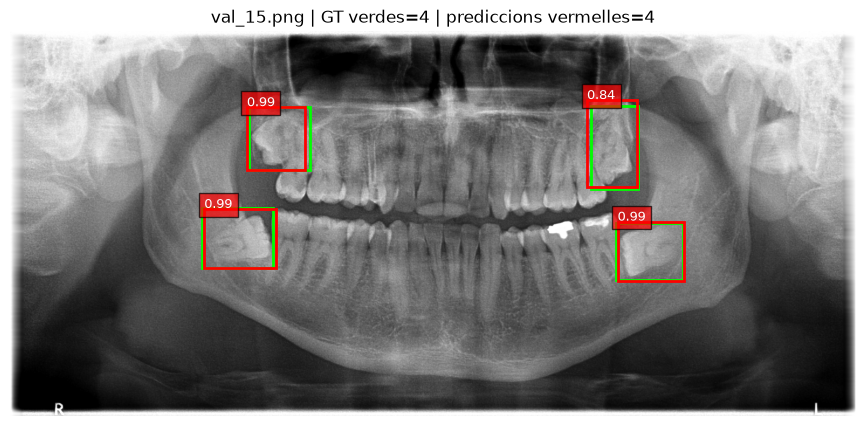

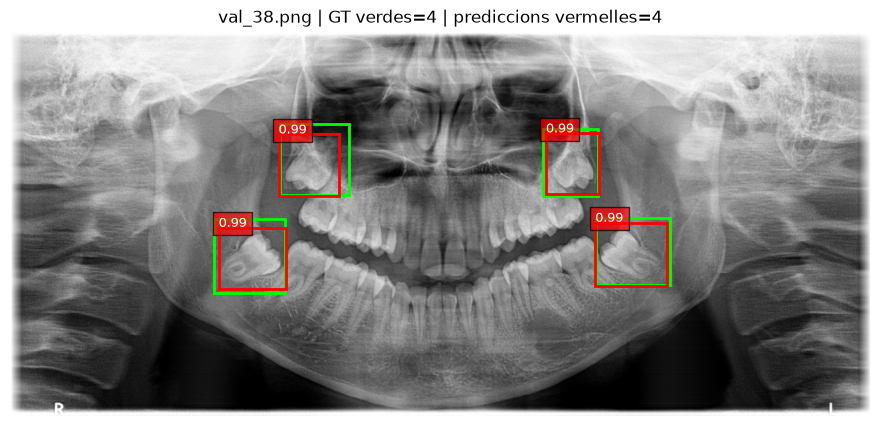

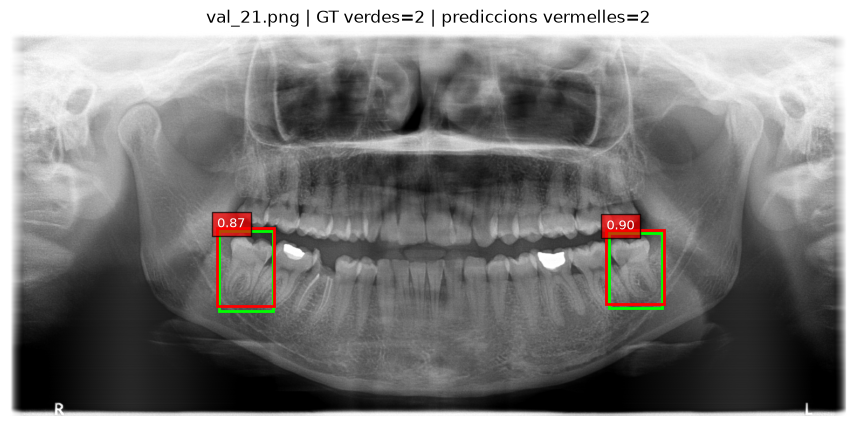

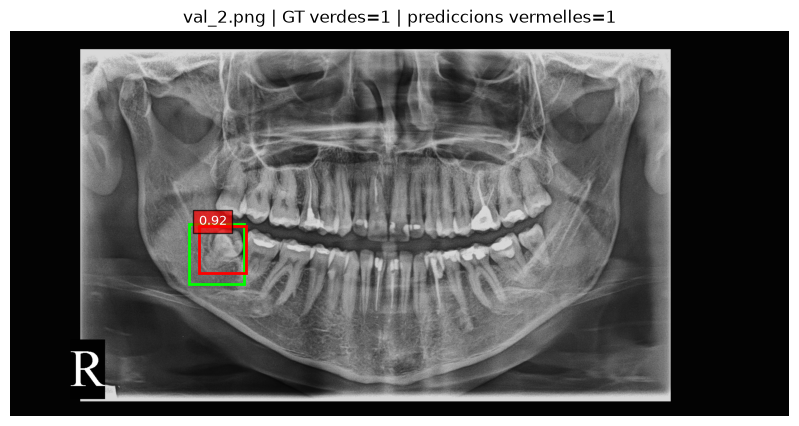

In [38]:
@torch.no_grad()
def show_detector_prediction(
    dataset,
    index,
    model=best_detector,
    score_threshold=0.30
):
    image, target = dataset[index]
    output = model([image.to(device)])[0]

    predicted_boxes = output["boxes"].cpu()
    predicted_scores = output["scores"].cpu()

    keep = predicted_scores >= score_threshold
    predicted_boxes = predicted_boxes[keep]
    predicted_scores = predicted_scores[keep]

    figure, axis = plt.subplots(figsize=(17, 5))
    axis.imshow(image.permute(1, 2, 0))

    # Ground truth en verd.
    for x_min, y_min, x_max, y_max in target["boxes"]:
        axis.add_patch(
            Rectangle(
                (x_min.item(), y_min.item()),
                (x_max - x_min).item(),
                (y_max - y_min).item(),
                edgecolor="lime",
                facecolor="none",
                linewidth=2
            )
        )

    # Prediccions en vermell.
    for box, score in zip(predicted_boxes, predicted_scores):
        x_min, y_min, x_max, y_max = box

        axis.add_patch(
            Rectangle(
                (x_min.item(), y_min.item()),
                (x_max - x_min).item(),
                (y_max - y_min).item(),
                edgecolor="red",
                facecolor="none",
                linewidth=2
            )
        )

        axis.text(
            x_min.item(),
            max(0, y_min.item() - 3),
            f"{score.item():.2f}",
            color="white",
            fontsize=9,
            bbox={"facecolor": "red", "alpha": 0.7}
        )

    axis.set_title(
        f"{dataset.file_name(index)} | "
        f"GT verdes={len(target['boxes'])} | "
        f"prediccions vermelles={len(predicted_boxes)}"
    )
    axis.axis("off")
    plt.show()


positive_indices = [
    index
    for index in range(len(val_dataset))
    if len(val_dataset[index][1]["boxes"]) > 0
][:4]

for index in positive_indices:
    show_detector_prediction(val_dataset, index)

In [ ]:
# El llindar de score modifica el compromís precisió-recall.
threshold_results = []

for score_threshold in [0.20, 0.30, 0.50, 0.70]:
    metrics = evaluate_detector(
        best_detector,
        val_loader,
        device,
        score_threshold=score_threshold,
        iou_threshold=0.50
    )

    threshold_results.append({
        "score_threshold": score_threshold,
        **metrics
    })

display(pd.DataFrame(threshold_results))

,score_threshold,tp,fp,fn,precision,recall,f1
0,0.2,36,20,4,0.642857,0.900,0.750000
1,0.3,36,17,4,0.679245,0.900,0.774194
2,0.5,36,12,4,0.750000,0.900,0.818182
3,0.7,35,10,5,0.777778,0.875,0.823529


# I ara fem probes extra

In [20]:
# Configuració que congelarem per analitzar el baseline
ANALYSIS_SCORE_THRESHOLD = 0.50
ANALYSIS_IOU_THRESHOLD = 0.50


@torch.inference_mode()
def collect_validation_predictions(
    model,
    data_loader,
    dataset,
    device
):
    """
    Executa el model una sola vegada i guarda les prediccions
    i els ground truths a CPU.
    
    Important: el DataLoader ha de tenir shuffle=False.
    """
    model.eval()

    records = []
    dataset_index = 0

    for images, targets in data_loader:
        images_device = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        outputs = model(images_device)

        for output, target in zip(outputs, targets):
            # En aquest detector la classe 1 és "impacted".
            is_impacted = output["labels"] == 1

            records.append({
                "dataset_index": dataset_index,
                "file_name": dataset.file_name(dataset_index),
                "image_id": int(
                    target["image_id"].reshape(-1)[0].item()
                ),
                "pred_boxes": (
                    output["boxes"][is_impacted]
                    .detach()
                    .cpu()
                ),
                "pred_scores": (
                    output["scores"][is_impacted]
                    .detach()
                    .cpu()
                ),
                "gt_boxes": target["boxes"].detach().cpu()
            })

            dataset_index += 1

    if dataset_index != len(dataset):
        raise RuntimeError(
            f"S'han processat {dataset_index} imatges, "
            f"però el dataset en té {len(dataset)}."
        )

    return records

best_detector = augmented_detector

validation_predictions = collect_validation_predictions(
    best_detector,
    val_loader,
    val_dataset,
    device
)

print(
    "Imatges de validation processades:",
    len(validation_predictions)
)

Imatges de validation processades: 50


### Matrius de cofusio clares

In [21]:
def match_detections_with_details(
    record,
    score_threshold=0.70,
    iou_threshold=0.50
):
    all_pred_boxes = record["pred_boxes"]
    all_pred_scores = record["pred_scores"]
    gt_boxes = record["gt_boxes"]

    # Conservem només les prediccions per sobre del threshold.
    selected_indices = torch.where(
        all_pred_scores >= score_threshold
    )[0]

    # Les ordenem de major a menor confiança.
    if len(selected_indices) > 0:
        selected_order = torch.argsort(
            all_pred_scores[selected_indices],
            descending=True
        )
        selected_indices = selected_indices[selected_order]

    pred_boxes = all_pred_boxes[selected_indices]
    pred_scores = all_pred_scores[selected_indices]

    if len(pred_boxes) > 0 and len(gt_boxes) > 0:
        iou_matrix = box_iou(pred_boxes, gt_boxes)
    else:
        iou_matrix = torch.zeros(
            (len(pred_boxes), len(gt_boxes)),
            dtype=torch.float32
        )

    matched_gt_indices = set()
    matches = []
    false_positives = []

    # Mateix criteri que utilitzàvem a evaluate_detector.
    for pred_index in range(len(pred_boxes)):
        if len(gt_boxes) == 0:
            false_positives.append({
                "pred_index": pred_index,
                "original_pred_index": int(
                    selected_indices[pred_index]
                ),
                "score": float(pred_scores[pred_index]),
                "best_iou": 0.0,
                "reason": "sense cap GT a la imatge"
            })
            continue

        best_iou, gt_index_tensor = (
            iou_matrix[pred_index].max(dim=0)
        )

        best_iou = float(best_iou)
        gt_index = int(gt_index_tensor)

        if (
            best_iou >= iou_threshold
            and gt_index not in matched_gt_indices
        ):
            matched_gt_indices.add(gt_index)

            matches.append({
                "pred_index": pred_index,
                "original_pred_index": int(
                    selected_indices[pred_index]
                ),
                "gt_index": gt_index,
                "score": float(pred_scores[pred_index]),
                "iou": best_iou
            })

        else:
            if best_iou >= iou_threshold:
                reason = "possible detecció duplicada"
            elif best_iou >= 0.10:
                reason = "solapament insuficient"
            else:
                reason = "sense GT propera"

            false_positives.append({
                "pred_index": pred_index,
                "original_pred_index": int(
                    selected_indices[pred_index]
                ),
                "score": float(pred_scores[pred_index]),
                "best_iou": best_iou,
                "reason": reason
            })

    unmatched_gt_indices = [
        gt_index
        for gt_index in range(len(gt_boxes))
        if gt_index not in matched_gt_indices
    ]

    false_negatives = []

    for gt_index in unmatched_gt_indices:
        # Mirem també les prediccions sota el threshold.
        if len(all_pred_boxes) > 0:
            ious_with_gt = box_iou(
                all_pred_boxes,
                gt_boxes[gt_index].unsqueeze(0)
            ).squeeze(1)

            best_pred_index = int(
                torch.argmax(ious_with_gt)
            )

            best_iou_all = float(
                ious_with_gt[best_pred_index]
            )
            best_score_all = float(
                all_pred_scores[best_pred_index]
            )
        else:
            best_iou_all = 0.0
            best_score_all = float("nan")

        if (
            best_iou_all >= iou_threshold
            and best_score_all < score_threshold
        ):
            reason = "bona box, però score sota el threshold"
        elif best_iou_all >= iou_threshold:
            reason = "possible conflicte de matching"
        elif best_iou_all >= 0.10:
            reason = "box mal localitzada"
        else:
            reason = "cap proposta propera"

        false_negatives.append({
            "gt_index": gt_index,
            "best_iou_any_prediction": best_iou_all,
            "best_score_any_prediction": best_score_all,
            "reason": reason
        })

    return {
        "pred_boxes": pred_boxes,
        "pred_scores": pred_scores,
        "gt_boxes": gt_boxes,
        "matches": matches,
        "false_positives": false_positives,
        "false_negatives": false_negatives
    }

In [22]:
analysis_records = []

per_image_rows = []
match_rows = []
false_positive_rows = []
false_negative_rows = []

for record in validation_predictions:
    details = match_detections_with_details(
        record,
        score_threshold=ANALYSIS_SCORE_THRESHOLD,
        iou_threshold=ANALYSIS_IOU_THRESHOLD
    )

    analysis_record = {
        **record,
        "details": details
    }
    analysis_records.append(analysis_record)

    per_image_rows.append({
        "dataset_index": record["dataset_index"],
        "file_name": record["file_name"],
        "n_ground_truth": len(details["gt_boxes"]),
        "n_predictions": len(details["pred_boxes"]),
        "tp": len(details["matches"]),
        "fp": len(details["false_positives"]),
        "fn": len(details["false_negatives"])
    })

    for match in details["matches"]:
        match_rows.append({
            "dataset_index": record["dataset_index"],
            "file_name": record["file_name"],
            "score": match["score"],
            "iou": match["iou"],
            "pred_index": match["pred_index"],
            "gt_index": match["gt_index"]
        })

    for false_positive in details["false_positives"]:
        false_positive_rows.append({
            "dataset_index": record["dataset_index"],
            "file_name": record["file_name"],
            "score": false_positive["score"],
            "best_iou": false_positive["best_iou"],
            "reason": false_positive["reason"]
        })

    for false_negative in details["false_negatives"]:
        false_negative_rows.append({
            "dataset_index": record["dataset_index"],
            "file_name": record["file_name"],
            "best_iou_any_prediction": (
                false_negative["best_iou_any_prediction"]
            ),
            "best_score_any_prediction": (
                false_negative["best_score_any_prediction"]
            ),
            "reason": false_negative["reason"]
        })


per_image_df = pd.DataFrame(per_image_rows)
matches_df = pd.DataFrame(match_rows)
false_positives_df = pd.DataFrame(false_positive_rows)
false_negatives_df = pd.DataFrame(false_negative_rows)

total_tp = int(per_image_df["tp"].sum())
total_fp = int(per_image_df["fp"].sum())
total_fn = int(per_image_df["fn"].sum())

precision = total_tp / (total_tp + total_fp)
recall = total_tp / (total_tp + total_fn)
f1 = 2 * precision * recall / (precision + recall)

summary_df = pd.DataFrame([{
    "score_threshold": ANALYSIS_SCORE_THRESHOLD,
    "iou_threshold": ANALYSIS_IOU_THRESHOLD,
    "tp": total_tp,
    "fp": total_fp,
    "fn": total_fn,
    "precision": precision,
    "recall": recall,
    "f1": f1
}])

display(summary_df)

,score_threshold,iou_threshold,tp,fp,fn,precision,recall,f1
0,0.5,0.5,35,15,5,0.7,0.875,0.777778


In [23]:
error_images_df = per_image_df[
    (per_image_df["fp"] > 0)
    | (per_image_df["fn"] > 0)
].copy()

error_images_df = error_images_df.sort_values(
    ["fn", "fp"],
    ascending=False
)

print("Imatges amb almenys un error:")
display(error_images_df)

print("\nFalsos positius:")
display(
    false_positives_df
    .sort_values("score", ascending=False)
    .reset_index(drop=True)
)

print("\nFalsos negatius:")
display(
    false_negatives_df
    .sort_values(
        "best_iou_any_prediction",
        ascending=False
    )
    .reset_index(drop=True)
)

Imatges amb almenys un error:


,dataset_index,file_name,n_ground_truth,n_predictions,tp,fp,fn
19,19,val_41.png,2,0,0,0,2
28,28,val_1.png,4,3,3,0,1
40,40,val_9.png,2,1,1,0,1
49,49,val_0.png,1,0,0,0,1
24,24,val_13.png,0,4,0,4,0
41,41,val_4.png,0,4,0,4,0
47,47,val_7.png,2,4,2,2,0
23,23,val_18.png,0,1,0,1,0
26,26,val_49.png,0,1,0,1,0
29,29,val_43.png,0,1,0,1,0



Falsos positius:


,dataset_index,file_name,score,best_iou,reason
0,41,val_4.png,0.993467,0.0,sense cap GT a la imatge
1,24,val_13.png,0.990463,0.0,sense cap GT a la imatge
2,41,val_4.png,0.989904,0.0,sense cap GT a la imatge
3,24,val_13.png,0.986029,0.0,sense cap GT a la imatge
4,41,val_4.png,0.985766,0.0,sense cap GT a la imatge
5,24,val_13.png,0.983444,0.0,sense cap GT a la imatge
6,41,val_4.png,0.982999,0.0,sense cap GT a la imatge
7,24,val_13.png,0.973448,0.0,sense cap GT a la imatge
8,26,val_49.png,0.969663,0.0,sense cap GT a la imatge
9,46,val_12.png,0.919549,0.0,sense GT propera



Falsos negatius:


,dataset_index,file_name,best_iou_any_prediction,best_score_any_prediction,reason
0,28,val_1.png,0.941783,0.391688,"bona box, però score sota el threshold"
1,19,val_41.png,0.914612,0.063756,"bona box, però score sota el threshold"
2,40,val_9.png,0.812901,0.104361,"bona box, però score sota el threshold"
3,19,val_41.png,0.000000,0.063756,cap proposta propera
4,49,val_0.png,0.000000,NaN,cap proposta propera


## Galeria d'errors

Imatges amb errors: 12


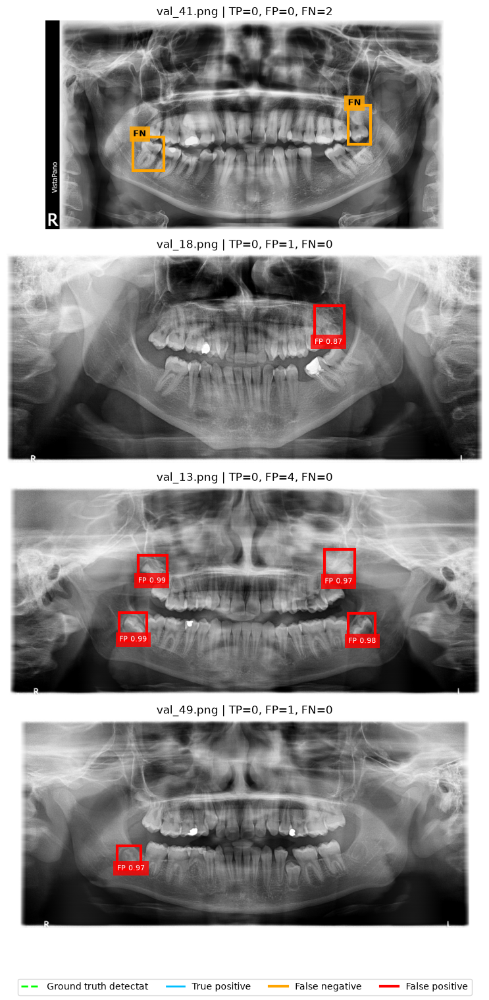

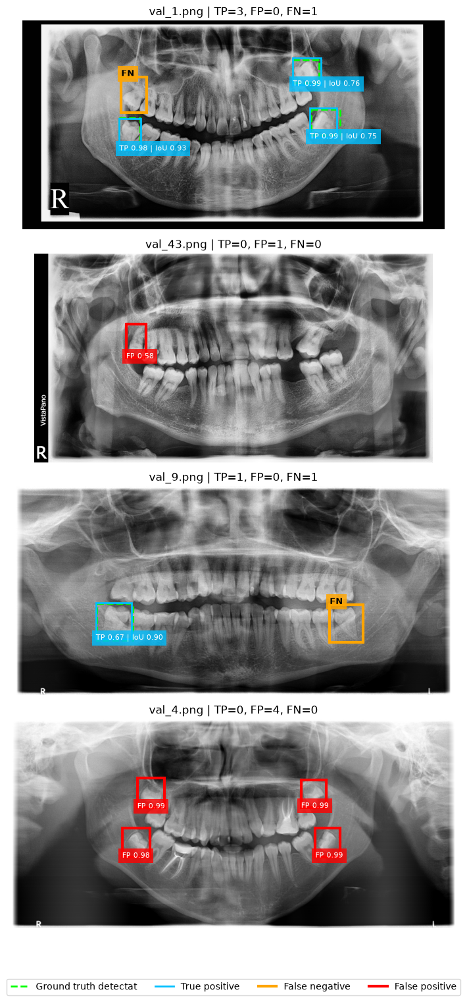

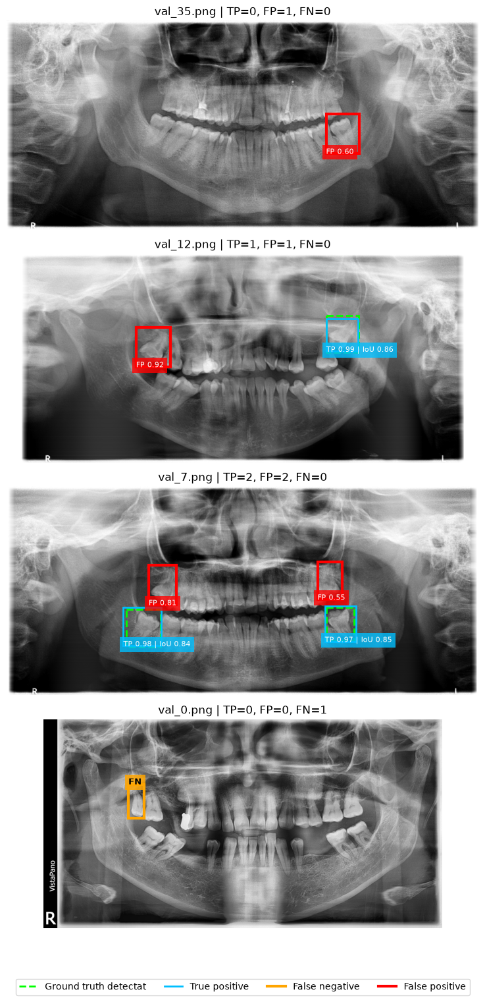

In [24]:
from matplotlib.lines import Line2D


def draw_detection_box(
    axis,
    box,
    color,
    linewidth=2,
    linestyle="-"
):
    x_min, y_min, x_max, y_max = [
        float(value)
        for value in box
    ]

    axis.add_patch(
        Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            edgecolor=color,
            facecolor="none",
            linewidth=linewidth,
            linestyle=linestyle
        )
    )


def draw_error_image(axis, record, dataset):
    image, _ = dataset[record["dataset_index"]]
    details = record["details"]

    axis.imshow(image.permute(1, 2, 0).numpy())

    false_negative_indices = {
        error["gt_index"]
        for error in details["false_negatives"]
    }

    false_positive_indices = {
        error["pred_index"]
        for error in details["false_positives"]
    }

    matches_by_prediction = {
        match["pred_index"]: match
        for match in details["matches"]
    }

    # Ground truths.
    for gt_index, gt_box in enumerate(details["gt_boxes"]):
        if gt_index in false_negative_indices:
            color = "orange"
            linewidth = 3
            linestyle = "-"
        else:
            color = "lime"
            linewidth = 2
            linestyle = "--"

        draw_detection_box(
            axis,
            gt_box,
            color=color,
            linewidth=linewidth,
            linestyle=linestyle
        )

        if gt_index in false_negative_indices:
            x_min = float(gt_box[0])
            y_min = float(gt_box[1])

            axis.text(
                x_min,
                max(0, y_min - 4),
                "FN",
                color="black",
                fontsize=9,
                fontweight="bold",
                bbox={
                    "facecolor": "orange",
                    "alpha": 0.85,
                    "edgecolor": "none"
                }
            )

    # Prediccions conservades amb threshold 0.7.
    for pred_index, (pred_box, score) in enumerate(
        zip(
            details["pred_boxes"],
            details["pred_scores"]
        )
    ):
        if pred_index in false_positive_indices:
            color = "red"
            label = f"FP {float(score):.2f}"
            linewidth = 3
        else:
            color = "deepskyblue"
            match = matches_by_prediction[pred_index]
            label = (
                f"TP {float(score):.2f} | "
                f"IoU {match['iou']:.2f}"
            )
            linewidth = 2

        draw_detection_box(
            axis,
            pred_box,
            color=color,
            linewidth=linewidth
        )

        x_min = float(pred_box[0])
        y_max = float(pred_box[3])

        axis.text(
            x_min,
            y_max + 3,
            label,
            color="white",
            fontsize=8,
            bbox={
                "facecolor": color,
                "alpha": 0.80,
                "edgecolor": "none"
            }
        )

    axis.set_title(
        f"{record['file_name']} | "
        f"TP={len(details['matches'])}, "
        f"FP={len(details['false_positives'])}, "
        f"FN={len(details['false_negatives'])}"
    )

    axis.axis("off")


def show_error_gallery(
    analysis_records,
    dataset,
    images_per_page=4
):
    records_with_errors = [
        record
        for record in analysis_records
        if (
            len(record["details"]["false_positives"]) > 0
            or len(record["details"]["false_negatives"]) > 0
        )
    ]

    print(
        "Imatges amb errors:",
        len(records_with_errors)
    )

    legend_handles = [
        Line2D(
            [0], [0],
            color="lime",
            linestyle="--",
            linewidth=2,
            label="Ground truth detectat"
        ),
        Line2D(
            [0], [0],
            color="deepskyblue",
            linewidth=2,
            label="True positive"
        ),
        Line2D(
            [0], [0],
            color="orange",
            linewidth=3,
            label="False negative"
        ),
        Line2D(
            [0], [0],
            color="red",
            linewidth=3,
            label="False positive"
        )
    ]

    for start in range(
        0,
        len(records_with_errors),
        images_per_page
    ):
        page_records = records_with_errors[
            start:start + images_per_page
        ]

        figure, axes = plt.subplots(
            len(page_records),
            1,
            figsize=(18, 3.8 * len(page_records)),
            squeeze=False
        )

        for axis, record in zip(
            axes[:, 0],
            page_records
        ):
            draw_error_image(
                axis,
                record,
                dataset
            )

        figure.legend(
            handles=legend_handles,
            loc="lower center",
            ncol=4
        )

        figure.tight_layout(
            rect=(0, 0.06, 1, 1)
        )
        plt.show()


show_error_gallery(
    analysis_records,
    val_dataset,
    images_per_page=4
)

#### Distribució d'IOU's

,n_true_positives,mean_iou,median_iou,q25_iou,q75_iou,min_iou,max_iou
0,35,0.838,0.851,0.804,0.902,0.628,0.941


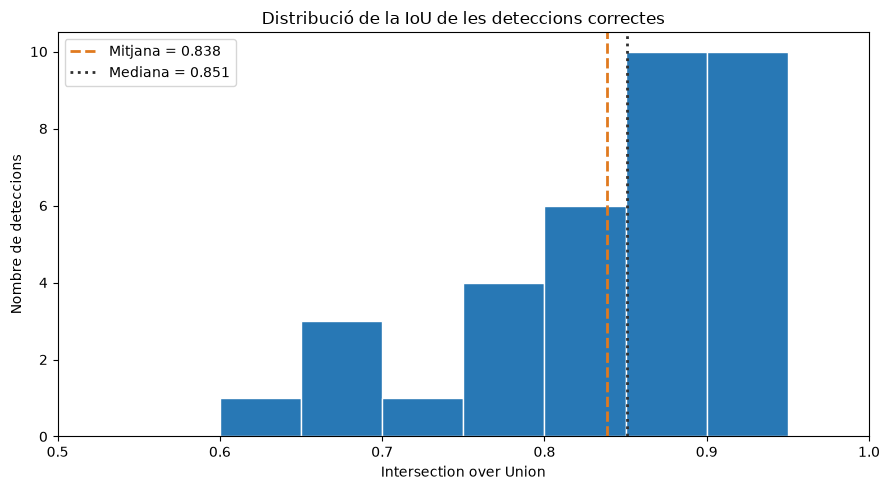

In [25]:
iou_summary_df = pd.DataFrame([{
    "n_true_positives": len(matches_df),
    "mean_iou": matches_df["iou"].mean(),
    "median_iou": matches_df["iou"].median(),
    "q25_iou": matches_df["iou"].quantile(0.25),
    "q75_iou": matches_df["iou"].quantile(0.75),
    "min_iou": matches_df["iou"].min(),
    "max_iou": matches_df["iou"].max()
}])

display(iou_summary_df.round(3))


figure, axis = plt.subplots(figsize=(9, 5))

bins = np.linspace(
    ANALYSIS_IOU_THRESHOLD,
    1.0,
    11
)

axis.hist(
    matches_df["iou"],
    bins=bins,
    color="#2878B5",
    edgecolor="white"
)

mean_iou = matches_df["iou"].mean()
median_iou = matches_df["iou"].median()

axis.axvline(
    mean_iou,
    color="#E07A1F",
    linestyle="--",
    linewidth=2,
    label=f"Mitjana = {mean_iou:.3f}"
)

axis.axvline(
    median_iou,
    color="#303030",
    linestyle=":",
    linewidth=2,
    label=f"Mediana = {median_iou:.3f}"
)

axis.set_title(
    "Distribució de la IoU de les deteccions correctes"
)
axis.set_xlabel("Intersection over Union")
axis.set_ylabel("Nombre de deteccions")
axis.set_xlim(0.50, 1.00)
axis.legend()

plt.tight_layout()
plt.show()

# AP 50 i mAP50-95 (ni idea k es això)

In [26]:
def compute_ap_at_iou(
    prediction_records,
    iou_threshold,
    max_detections_per_image=100
):
    """
    AP per a una classe utilitzant interpolació de 101 punts.
    """

    ground_truths_by_image = {}
    detections = []
    total_ground_truths = 0

    for record in prediction_records:
        image_index = record["dataset_index"]
        gt_boxes = record["gt_boxes"]

        ground_truths_by_image[image_index] = gt_boxes
        total_ground_truths += len(gt_boxes)

        scores = record["pred_scores"]
        boxes = record["pred_boxes"]

        order = torch.argsort(
            scores,
            descending=True
        )[:max_detections_per_image]

        for pred_index in order:
            detections.append({
                "image_index": image_index,
                "score": float(scores[pred_index]),
                "box": boxes[pred_index]
            })

    if total_ground_truths == 0:
        raise ValueError(
            "No hi ha ground truths per calcular AP."
        )

    # Ordenació global de totes les prediccions.
    detections = sorted(
        detections,
        key=lambda detection: detection["score"],
        reverse=True
    )

    matched_gt_by_image = {
        image_index: set()
        for image_index in ground_truths_by_image
    }

    true_positives = []
    false_positives = []
    detection_scores = []

    for detection in detections:
        image_index = detection["image_index"]
        predicted_box = detection["box"]
        gt_boxes = ground_truths_by_image[image_index]

        detection_scores.append(detection["score"])

        if len(gt_boxes) == 0:
            true_positives.append(0)
            false_positives.append(1)
            continue

        ious = box_iou(
            predicted_box.unsqueeze(0),
            gt_boxes
        ).squeeze(0)

        # No permetem tornar a assignar una GT ja utilitzada.
        for matched_index in matched_gt_by_image[image_index]:
            ious[matched_index] = -1.0

        best_iou, gt_index_tensor = ious.max(dim=0)

        best_iou = float(best_iou)
        gt_index = int(gt_index_tensor)

        if best_iou >= iou_threshold:
            true_positives.append(1)
            false_positives.append(0)
            matched_gt_by_image[image_index].add(gt_index)
        else:
            true_positives.append(0)
            false_positives.append(1)

    if len(detections) == 0:
        empty_curve = pd.DataFrame(
            columns=[
                "score",
                "recall",
                "precision",
                "precision_envelope"
            ]
        )
        return 0.0, empty_curve

    cumulative_tp = np.cumsum(
        np.asarray(true_positives, dtype=float)
    )
    cumulative_fp = np.cumsum(
        np.asarray(false_positives, dtype=float)
    )

    recall = cumulative_tp / total_ground_truths

    precision = cumulative_tp / np.maximum(
        cumulative_tp + cumulative_fp,
        1e-12
    )

    # Fa que la precisió sigui monòtona.
    precision_envelope = np.maximum.accumulate(
        precision[::-1]
    )[::-1]

    recall_levels = np.linspace(0, 1, 101)

    interpolated_precision = []

    for recall_level in recall_levels:
        valid_positions = recall >= recall_level

        if np.any(valid_positions):
            interpolated_precision.append(
                precision_envelope[
                    valid_positions
                ].max()
            )
        else:
            interpolated_precision.append(0.0)

    average_precision = float(
        np.mean(interpolated_precision)
    )

    curve_df = pd.DataFrame({
        "score": detection_scores,
        "recall": recall,
        "precision": precision,
        "precision_envelope": precision_envelope
    })

    return average_precision, curve_df

In [27]:
iou_thresholds = np.round(
    np.arange(0.50, 1.00, 0.05),
    2
)

ap_rows = []
pr_curve_at_50 = None

for iou_threshold in iou_thresholds:
    average_precision, curve_df = compute_ap_at_iou(
        validation_predictions,
        iou_threshold=iou_threshold
    )

    ap_rows.append({
        "iou_threshold": iou_threshold,
        "average_precision": average_precision
    })

    if np.isclose(iou_threshold, 0.50):
        pr_curve_at_50 = curve_df


ap_by_iou_df = pd.DataFrame(ap_rows)

ap50 = float(
    ap_by_iou_df.loc[
        np.isclose(
            ap_by_iou_df["iou_threshold"],
            0.50
        ),
        "average_precision"
    ].iloc[0]
)

map_50_95 = float(
    ap_by_iou_df["average_precision"].mean()
)

standard_metrics_df = pd.DataFrame([{
    "AP50": ap50,
    "mAP50_95": map_50_95,
    "n_ground_truth_boxes": sum(
        len(record["gt_boxes"])
        for record in validation_predictions
    )
}])

display(standard_metrics_df.round(4))
display(ap_by_iou_df.round(4))

,AP50,mAP50_95,n_ground_truth_boxes
0,0.7361,0.4816,40


,iou_threshold,average_precision
0,0.50,0.7361
1,0.55,0.7361
2,0.60,0.7361
3,0.65,0.7167
4,0.70,0.5796
5,0.75,0.5551
6,0.80,0.4064
7,0.85,0.2637
8,0.90,0.0857
9,0.95,0.0000


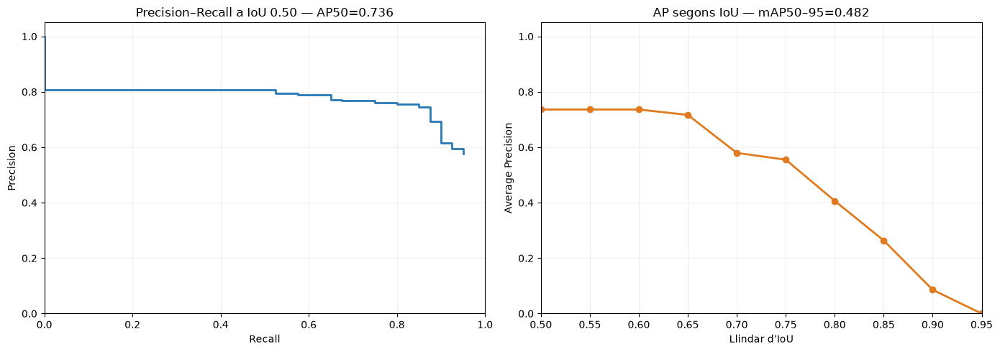

In [28]:
figure, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Corba precision-recall a IoU 0.50.
axes[0].step(
    np.concatenate([
        [0.0],
        pr_curve_at_50["recall"].to_numpy()
    ]),
    np.concatenate([
        [1.0],
        pr_curve_at_50[
            "precision_envelope"
        ].to_numpy()
    ]),
    where="post",
    color="#2878B5",
    linewidth=2
)

axes[0].set_title(
    f"Precision–Recall a IoU 0.50 — AP50={ap50:.3f}"
)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.2)

# Com cau l'AP quan demanem boxes més precises.
axes[1].plot(
    ap_by_iou_df["iou_threshold"],
    ap_by_iou_df["average_precision"],
    marker="o",
    color="#E07A1F",
    linewidth=2
)

axes[1].set_title(
    f"AP segons IoU — mAP50–95={map_50_95:.3f}"
)
axes[1].set_xlabel("Llindar d’IoU")
axes[1].set_ylabel("Average Precision")
axes[1].set_xlim(0.50, 0.95)
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Guardem resultats

In [29]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

summary_df.to_csv(
    results_dir / "baseline_summary.csv",
    index=False
)

per_image_df.to_csv(
    results_dir / "per_image_detection_results.csv",
    index=False
)

matches_df.to_csv(
    results_dir / "matched_detections.csv",
    index=False
)

false_positives_df.to_csv(
    results_dir / "false_positives.csv",
    index=False
)

false_negatives_df.to_csv(
    results_dir / "false_negatives.csv",
    index=False
)

ap_by_iou_df.to_csv(
    results_dir / "average_precision_by_iou.csv",
    index=False
)

baseline_config = {
    "checkpoint": str(checkpoint_path),
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "score_threshold": ANALYSIS_SCORE_THRESHOLD,
    "matching_iou_threshold": ANALYSIS_IOU_THRESHOLD,
    "detector": "Faster R-CNN ResNet50 FPN",
    "target_class": "impacted",
    "validation_images": len(val_dataset)
}

with open(
    results_dir / "baseline_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        baseline_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Resultats guardats a:", results_dir.resolve())

Resultats guardats a: C:\Users\Neo-PC\Desktop\rxDental\results


# Hard Negative Mining:

Anem a intentar entrenar el model explícitament per a que no detecti els 3rs molars no impactats

In [30]:
train_mining_loader = DataLoader(
    train_mining_dataset,
    batch_size=1,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(
    "Imatges disponibles per fer mining:",
    len(train_mining_dataset)
)

print(
    "Augmentació activada:",
    train_mining_dataset.augment
)

Imatges disponibles per fer mining: 705
Augmentació activada: False


In [39]:
@torch.inference_mode()
def find_hard_negatives(
    model,
    data_loader,
    dataset,
    device,
    score_threshold=0.80
):
    """
    Busca imatges de train sense cap impactació anotada
    on el model prediu almenys una impactació amb una
    confiança igual o superior a score_threshold. En aquest cas 0.8
    """

    model.eval()

    hard_negative_records = []
    dataset_index = 0

    for images, targets in data_loader:
        image = images[0]
        target = targets[0]

        # Nombre d'impactacions reals segons el JSON.
        n_ground_truth = len(target["boxes"])

        # Només ens interessen les imatges negatives.
        if n_ground_truth == 0:
            output = model(
                [image.to(device)]
            )[0]

            predicted_boxes = (
                output["boxes"]
                .detach()
                .cpu()
            )

            predicted_scores = (
                output["scores"]
                .detach()
                .cpu()
            )

            predicted_labels = (
                output["labels"]
                .detach()
                .cpu()
            )

            # Classe 1 = impactació.
            keep = (
                (predicted_labels == 1)
                & (
                    predicted_scores
                    >= score_threshold
                )
            )

            selected_boxes = predicted_boxes[keep]
            selected_scores = predicted_scores[keep]

            if len(selected_scores) > 0:
                hard_negative_records.append({
                    "dataset_index": dataset_index,
                    "file_name": dataset.file_name(
                        dataset_index
                    ),
                    "n_predictions": len(
                        selected_scores
                    ),
                    "max_score": float(
                        selected_scores.max()
                    ),
                    "mean_score": float(
                        selected_scores.mean()
                    ),
                    "predicted_boxes": selected_boxes,
                    "predicted_scores": selected_scores
                })

        dataset_index += 1

    hard_negative_records.sort(
        key=lambda record: record["max_score"],
        reverse=True
    )

    return hard_negative_records

In [32]:
mining_model = augmented_detector

hard_negative_records = find_hard_negatives(
    mining_model,
    train_mining_loader,
    train_mining_dataset,
    device,
    score_threshold=0.80
)

hard_negative_df = pd.DataFrame([
    {
        "dataset_index": record["dataset_index"],
        "file_name": record["file_name"],
        "n_predictions": record["n_predictions"],
        "max_score": record["max_score"],
        "mean_score": record["mean_score"]
    }
    for record in hard_negative_records
])

print(
    "Hard negatives trobats:",
    len(hard_negative_df)
)

display(
    hard_negative_df.head(20)
)

Hard negatives trobats: 34


,dataset_index,file_name,n_predictions,max_score,mean_score
0,428,train_215.png,2,0.988576,0.985898
1,200,train_506.png,4,0.987412,0.970518
2,291,train_252.png,4,0.987130,0.978963
3,299,train_584.png,2,0.985132,0.977950
4,481,train_448.png,1,0.983368,0.983368
5,172,train_247.png,2,0.981203,0.959011
6,151,train_511.png,1,0.980469,0.980469
7,270,train_416.png,2,0.978667,0.976083
8,488,train_99.png,1,0.976718,0.976718
9,99,train_538.png,4,0.976260,0.972509


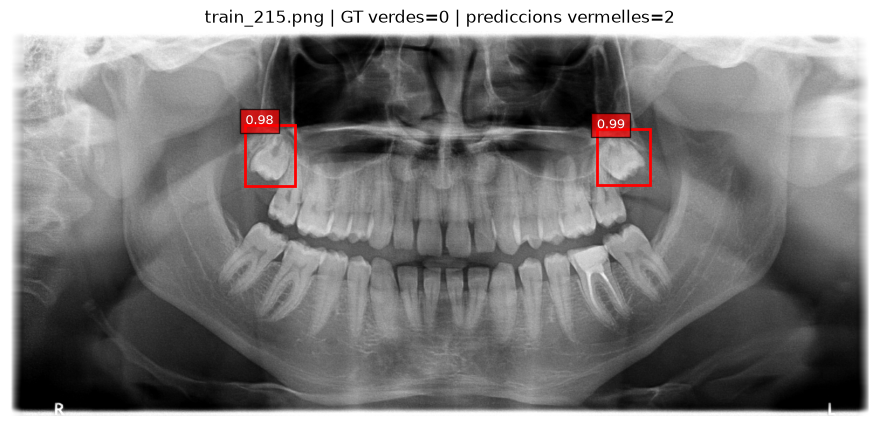

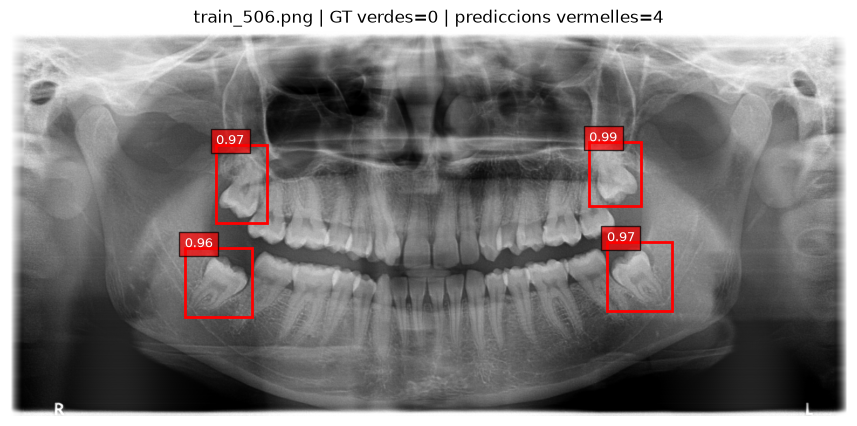

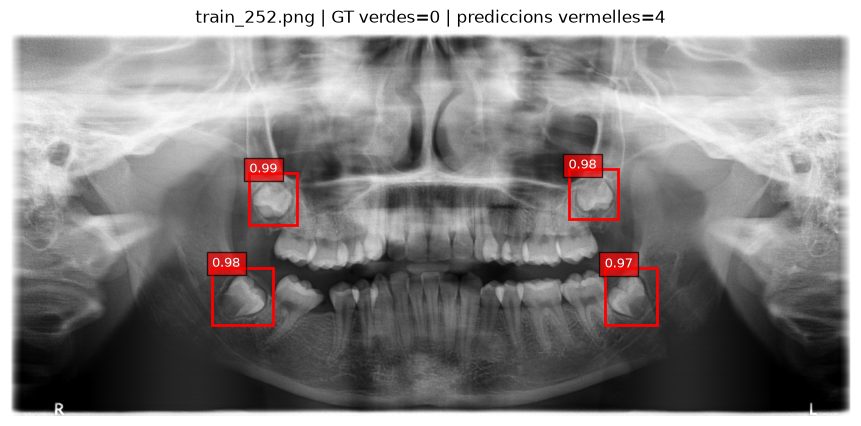

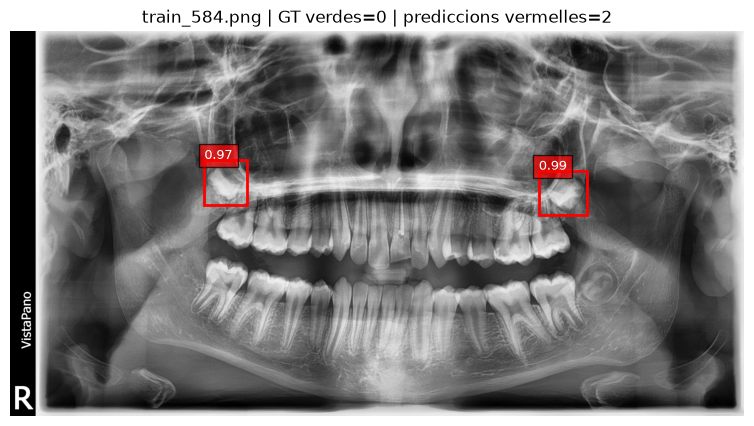

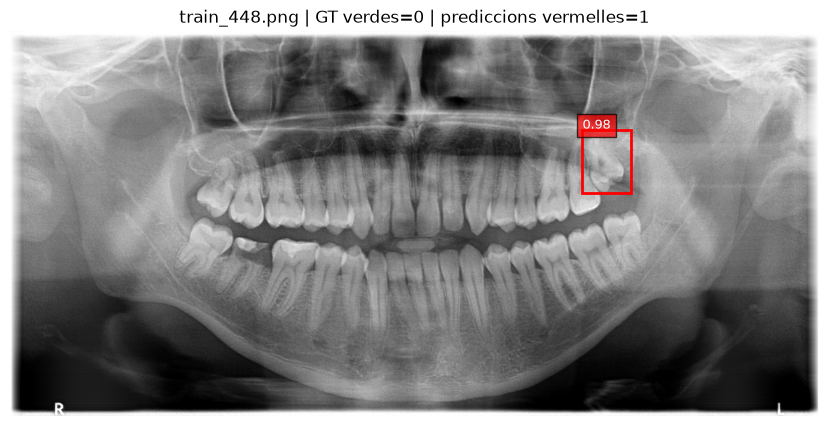

...

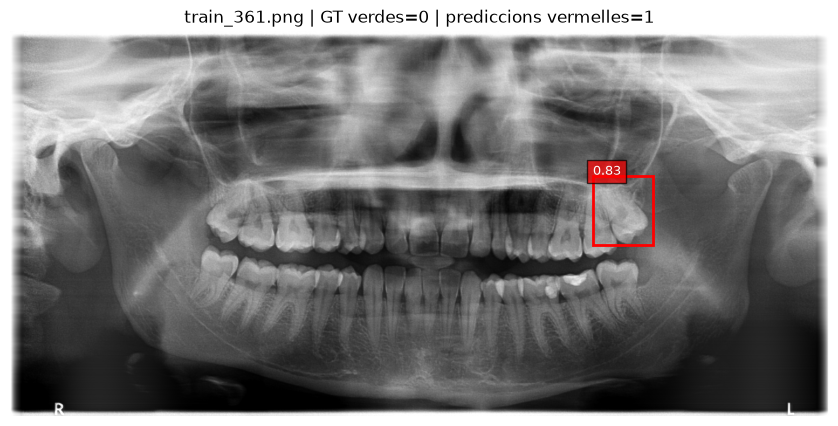

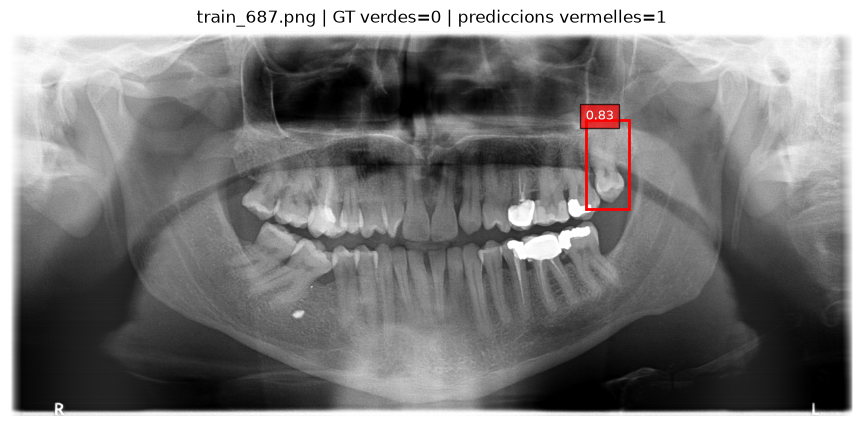

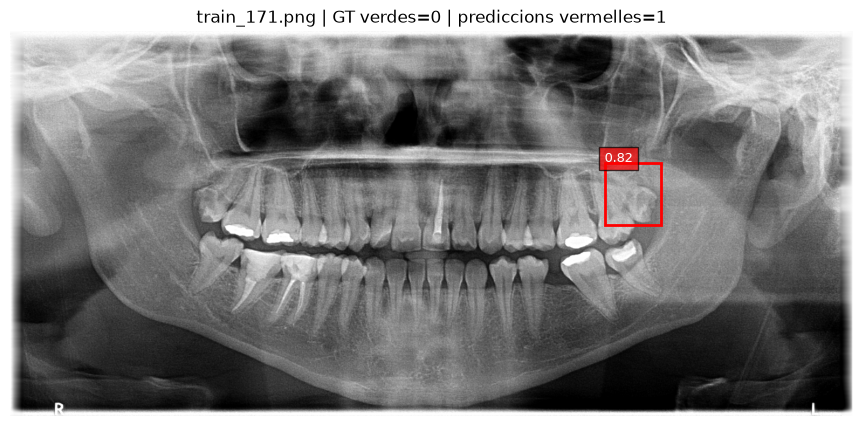

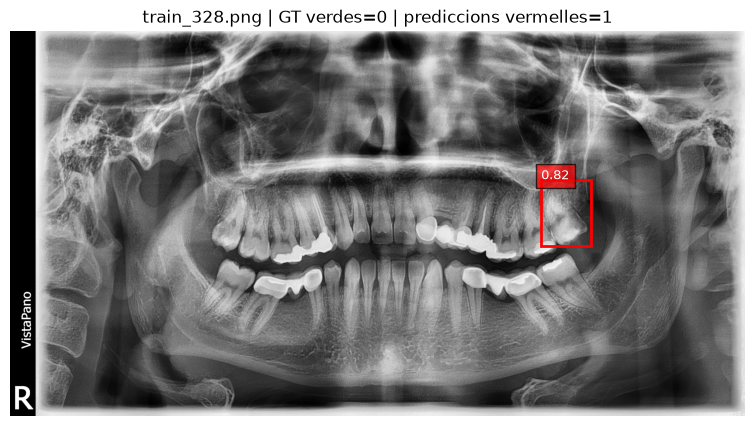

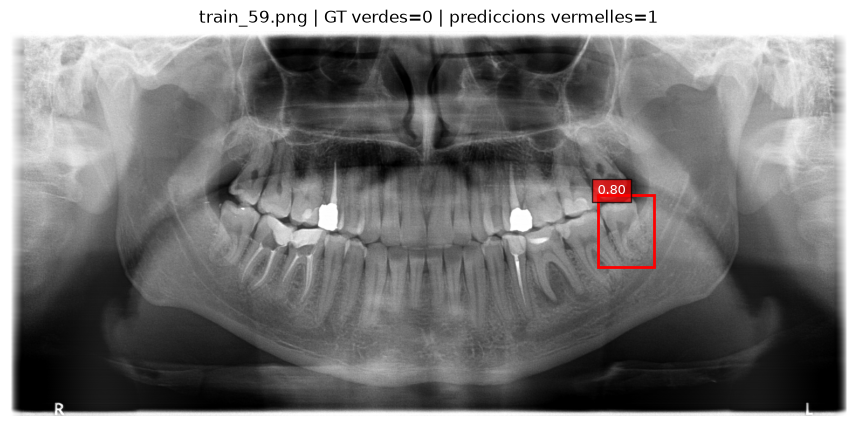

In [40]:
n_examples = max(
    30,
    len(hard_negative_records)
)

for record in hard_negative_records[:n_examples]:
    show_detector_prediction(
        train_mining_dataset,
        record["dataset_index"],
        model=mining_model,
        score_threshold=0.80
    )